# Floor-posture radar — exploring the data

A person is lying on the floor. A ceiling-mounted mmWave radar looks down at
them, and a camera next to it records what actually happened.

This notebook walks through what is in a recording, what the radar config
tells you about the limits of the sensor, and how to look at a frame. Run it
top to bottom once, then use the viewer sections to browse.

**Setup** — from the bundle root (the folder holding `data/` and `recorder/`):

```bash
python -m venv venv

venv\Scripts\activate                 # Windows cmd / PowerShell
source venv/Scripts/activate          # Windows, git-bash
source venv/bin/activate              # macOS / Linux

python -m pip install -e recorder
python -m pip install jupyter ipykernel
python -m ipykernel install --user --name floor-posture --display-name "floor-posture"
python -m jupyter lab
```

Then pick the **floor-posture** kernel in Jupyter (Kernel → Change Kernel).

That registration step is the one people skip, and it is the one that matters:
`pip install` puts the reader in your virtualenv, but `jupyter lab` may well
launch a Jupyter installed somewhere else, whose kernel is a different Python
that has never heard of it. Symptom: `ModuleNotFoundError: No module named
'vt_radar'`. Using `python -m ...` throughout keeps everything pinned to the
interpreter you just activated.

If you hit it anyway, the next cell falls back to loading the reader straight
out of `recorder/` and prints which Python it is actually running, so you are
not stuck.

In [1]:
import os
import sys
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Bundle root. Adjust if you moved the notebook out of the bundle folder.
ROOT = "../../data/raw/floor_posture_dataset/"
if not os.path.isdir(os.path.join(ROOT, "data")):
    raise SystemExit(
        f"No data/ folder under {os.path.abspath(ROOT)}.\n"
        "Set ROOT to the folder that contains data/, recorder/ and previews/."
    )

RECORDER = os.path.abspath(os.path.join(ROOT, "recorder"))


def _load_reader():
    '''Import the bits of the reader this notebook uses.'''
    from loguru import logger
    from vt_radar.data.dataset import TLVDataset
    from vt_radar.data.rangedoppler import RangeDoppler
    from vt_radar.config.ti_config import ConfigFile
    return logger, TLVDataset, RangeDoppler, ConfigFile


# The reader lives in recorder/. If it is not installed in the kernel running
# this notebook, fall back to the copy sitting next to us rather than making you
# fight with virtualenvs -- a common way to lose an afternoon is to pip install
# into one Python and run Jupyter from another.
try:
    logger, TLVDataset, RangeDoppler, ConfigFile = _load_reader()
except ModuleNotFoundError:
    if os.path.isdir(RECORDER) and RECORDER not in sys.path:
        sys.path.insert(0, RECORDER)
    try:
        logger, TLVDataset, RangeDoppler, ConfigFile = _load_reader()
        print(f"vt_radar was not installed in this kernel; loaded it from {RECORDER}")
    except ModuleNotFoundError as exc:
        raise SystemExit(
            f"Cannot import '{exc.name}'.\n\n"
            f"This notebook is running this interpreter:\n    {sys.executable}\n\n"
            "Install the reader and its dependencies into THAT one:\n"
            f'    "{sys.executable}" -m pip install -e "{RECORDER}"\n\n'
            "then restart the kernel (Kernel -> Restart).\n\n"
            "Copy the path exactly. The usual cause of this error is pip installing\n"
            "into one Python while Jupyter runs a different one."
        ) from exc

logger.remove()          # the loader is chatty; silence it for the notebook

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["image.cmap"] = "viridis"

print("bundle  :", os.path.abspath(ROOT))
print("python  :", sys.executable)
print("reader  :", os.path.dirname(sys.modules["vt_radar.data.dataset"].__file__))

bundle  : /Users/sigurdurhaukur/Documents/rug/ai-engineering/data/raw/floor_posture_dataset
python  : /Users/sigurdurhaukur/Documents/rug/ai-engineering/.venv/bin/python
reader  : /Users/sigurdurhaukur/Documents/rug/ai-engineering/data/raw/floor_posture_dataset/recorder/vt_radar/data


## 1. What's in the bundle

`MANIFEST.csv` has one row per recording. Every recording is a directory of
`data_*.h5` chunks (500 frames each) plus the `.cfg` the radar was running.

In [2]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"))
shapes = pd.read_csv(os.path.join(ROOT, "HEATMAP_SHAPES.csv"))
man = man.merge(shapes[["rec", "heatmap", "cfg"]], left_on="dataset", right_on="rec", how="left")

available = {os.path.basename(p) for p in glob.glob(os.path.join(ROOT, "data", "*", "*"))}
man["present"] = man.dataset.isin(available)

print(f"{man.present.sum()} of {len(man)} recordings present in this folder")
print(f"{man.loc[man.present, 'frames'].sum():,} frames, {man.loc[man.present, 'size_mb'].sum():.0f} MB")
man.loc[man.present, ["dataset", "room", "frames", "size_mb", "heatmap", "recorded", "has_labels"]]

35 of 35 recordings present in this folder
49,900 frames, 4982 MB


,dataset,room,frames,size_mb,heatmap,recorded,has_labels
0,2309__20230927_145000,room1,900,86.0,"(64, 16)",2023-09-27 12:51,False
1,2310__20231006_154117,room1,2600,245.7,"(64, 16)",2023-10-06 13:45,True
2,2310__20231006_155527,room1,1500,138.8,"(64, 16)",2023-10-06 13:57,False
3,2310__20231006_161334,room1,1500,143.8,"(64, 16)",2023-10-06 14:15,False
4,2310__20231020_143847,room1,1500,128.7,"(64, 16)",2023-10-20 12:39,False
5,2310__20231027_134002,room1,1800,176.6,"(64, 16)",2023-10-27 11:45,False
6,2310__20231027_140700,room1,1700,147.0,"(64, 16)",2023-10-27 12:12,False
7,2310__20231027_142000,room1,1500,135.9,"(64, 16)",2023-10-27 12:20,False
8,2310__20231027_143141,room1,2000,186.6,"(64, 16)",2023-10-27 12:37,False
9,2310__20231027_150820,room1,1700,156.4,"(64, 16)",2023-10-27 13:13,False


If you only have part 1 of the transfer, most rows will show `present = False`.
Everything below works on whatever you do have.

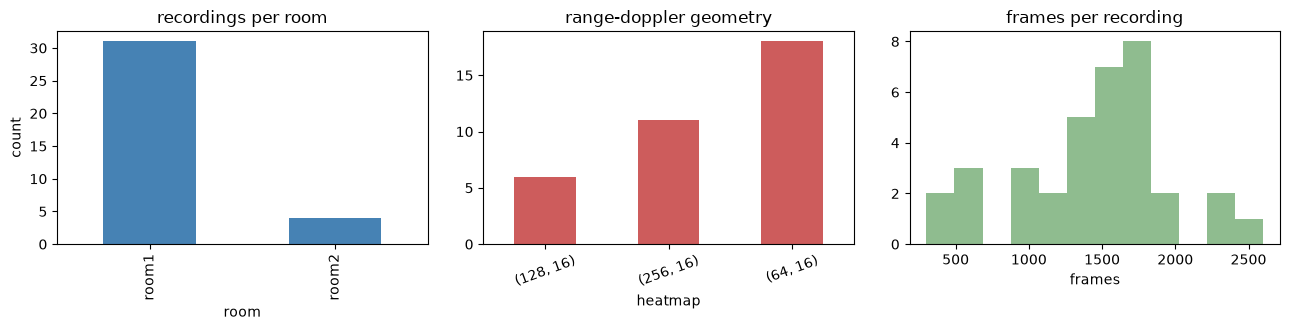

In [3]:
present = man[man.present].copy()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
present.groupby("room").size().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("recordings per room"); ax[0].set_ylabel("count")
present.groupby("heatmap").size().plot.bar(ax=ax[1], color="indianred")
ax[1].set_title("range-doppler geometry"); ax[1].tick_params(axis="x", rotation=20)
ax[2].hist(present.frames, bins=12, color="darkseagreen")
ax[2].set_title("frames per recording"); ax[2].set_xlabel("frames")
plt.tight_layout()
plt.show()

### The heatmap is not one fixed size

The doppler axis is always 16 bins, but the range axis is 64, 128 or 256
depending on the radar config. **You cannot stack recordings into one array
without handling this.** The next section shows where that number comes from.

## 2. The radar config — what the sensor can and cannot see

Each recording carries the `.cfg` that was actually sent to the radar. It fixes
the physics of what you're looking at: how finely range is resolved, how far the
radar sees, and how fast something must move to register a doppler shift.

`ConfigFile` parses it and derives the useful quantities.

In [4]:
def load_cfg(rec):
    '''Parse the .cfg that shipped with a recording.'''
    d = rec_dir(rec)
    cfgs = sorted(glob.glob(os.path.join(d, "*.cfg")))
    if not cfgs:
        raise FileNotFoundError(f"no .cfg in {d}")
    c = ConfigFile()
    c.parseCfg(cfgs[0])
    return c, os.path.basename(cfgs[0])


def rec_dir(rec):
    '''Directory for a recording name, whichever room it is in.'''
    hits = glob.glob(os.path.join(ROOT, "data", "*", rec))
    if not hits:
        raise FileNotFoundError(f"{rec} is not in this folder (another zip part?)")
    return hits[0]


def frames_of(rec, order="capture"):
    '''Every frame of a recording, in the order you asked for.

    The .h5 files are read alphabetically -- data_10 lands right after data_1 --
    so the frames do NOT arrive in the order they were captured. In
    2310__20231020_143847 the 700th frame jumps from frame 1501 back to frame
    201. Anything plotted against time has to fix that first, or the image
    doubles back on itself partway through.

    order="capture"  sorted by the frame's own timestamp. What you want for a
                     range-time image, and what the labels/*.csv files are in.
    order="file"     the raw reading order. Only for the .npy label arrays from
                     earlier work, which were written in that order.
    '''
    frames = list(TLVDataset(rec_dir(rec)))
    if order == "capture":
        frames.sort(key=lambda f: f.timestamp)
    return frames

def cfg_summary(rec):
    c, name = load_cfg(rec)
    s = c.sensor()
    return {
        "recording": rec,
        "cfg": name,
        "range_res_m": round(s.range_resolution, 4),
        "range_max_m": round(s.range_max, 2),
        "range_bins": s.num_range_bins,
        "doppler_bins": s.num_doppler_bins,
        "doppler_res_m_s": round(s.doppler_resolution, 4),
        "max_velocity_m_s": round(s.max_velocity, 3),
        "tx": s.num_tx_antennas,
        "rx": s.num_rx_antennas,
    }


rows = []
for rec in present.dataset:
    try:
        rows.append(cfg_summary(rec))
    except Exception as e:
        rows.append({"recording": rec, "cfg": f"<{type(e).__name__}>"})
cfgs = pd.DataFrame(rows)
cfgs

,recording,cfg,range_res_m,range_max_m,range_bins,doppler_bins,doppler_res_m_s,max_velocity_m_s,tx,rx
0,2309__20230927_145000,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
1,2310__20231006_154117,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
2,2310__20231006_155527,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
3,2310__20231006_161334,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
4,2310__20231020_143847,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
5,2310__20231027_134002,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
6,2310__20231027_140700,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
7,2310__20231027_142000,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
8,2310__20231027_143141,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
9,2310__20231027_150820,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4


Read that table as the sensor's limits:

- **`range_res_m`** — two things closer together than this merge into one range
  bin. A lying person is roughly 0.4 m deep, so at 4 cm resolution they span
  ~10 bins; at 17 cm they span two or three.
- **`range_max_m`** — beyond this the radar reports nothing.
- **`max_velocity_m_s`** — the fastest unambiguous motion. Breathing and small
  shifts sit near zero doppler, which is exactly where a still person lives.
- **`range_bins × doppler_bins`** is the heatmap shape you get for that
  recording.

The distinct configs in the bundle:

In [5]:
cols = ["cfg", "range_res_m", "range_max_m", "range_bins", "doppler_bins",
        "doppler_res_m_s", "max_velocity_m_s", "tx", "rx"]
distinct = cfgs.dropna(subset=["range_bins"]).drop_duplicates(subset=cols)[cols]
distinct.reset_index(drop=True)

,cfg,range_res_m,range_max_m,range_bins,doppler_bins,doppler_res_m_s,max_velocity_m_s,tx,rx
0,Experiment_1.cfg,0.7682,39.33,64,16,0.0248,0.199,3,4
1,Config_4.cfg,0.0237,4.85,256,16,0.1297,1.038,3,4
2,Config_4.cfg,0.0421,4.85,256,16,0.1326,1.061,3,4
3,Thursday(02.11)_+noise.cfg,0.0468,2.40,64,16,0.2494,1.995,3,4
4,Thursday(02.11)_Exp_1.cfg,0.0468,2.40,64,16,0.2494,1.995,3,4
5,Config_3.cfg,0.0468,2.40,64,16,0.2506,2.005,3,4
6,Config_3.cfg,0.0234,2.40,128,16,0.2444,1.955,3,4
7,Config_5.cfg,0.0436,4.46,128,16,0.1206,0.965,3,4


Same scene, very different instruments. Two things in that table are worth
staring at:

**Range resolution spans roughly 0.02 m to 0.77 m — a factor of thirty.**
`Experiment_1.cfg` (the September/October recordings) uses a narrow sweep, so a
range bin is 77 cm. A person lying down is ~40 cm deep, i.e. *less than one
bin*: they are a single blob. Under `Config_4.cfg` the same person spans tens of
bins and you can see their shape. These are not interchangeable recordings.

**Maximum unambiguous velocity spans 0.2 m/s to 2.0 m/s.** `Experiment_1.cfg`
tops out at 0.199 m/s — anything faster aliases and folds back into the doppler
axis. Fine for someone lying still, misleading the moment they move.

And note the same *filename* appears twice with different numbers —
`Config_3.cfg` is 64 bins in one recording and 128 in another. **Key off the
parsed contents, never off the config's name.**

These figures describe the config that was sent to the radar. Treat them as
strong evidence rather than gospel, and sanity-check against the data: if the
geometry says the person should be at bin 30 and the energy sits at bin 3,
believe the data.

You can also dump the whole parsed config for one recording:

In [6]:
c, name = load_cfg(present.dataset.iloc[0])
print(name)
c.describe()

Experiment_1.cfg
----------------------  ------------
Profile                 #0
Start frequency         60.0 GHz
Frequency Slope         38.11 MHz/us
ADC sampling frequency  12.5 Ms/s
Samples per chirp       64.0
Idle Time               2070.0 us
ADC Valid Start Time    7.0
Ramp End Time           13.12 us
TX Start Time           1.0
----------------------  ------------
THUS: ADC Sampling Time 5.12
THUS: Sweep bandwidth 195.1232

-------------  --
NumberOfLoops  16
-------------  --
--------------------  -----
Sub-frame Index       -1
Processing Direction  Range
Minimum Value         0.0
Maximum Value         39.35
--------------------  -----
--------------------  -------
Sub-frame Index       -1
Processing Direction  Doppler
Minimum Value         -0.2
Maximum Value         0.2
--------------------  -------
----------------------------  -
detectedObjects               0
logMagRange                   0
noiseProfile                  0
rangeAzimuthElevationHeatMap  0
rangeDopplerHeatMap 

## 3. Opening a recording

`TLVDataset` takes a directory, finds the `.cfg` beside the data, and yields
`Frame` objects.

In [7]:
REC = present.dataset.iloc[0]          # change this to explore another recording
frames = frames_of(REC)          # capture order -- see frames_of()
print(f"{REC}: {len(frames)} frames")

f = frames[len(frames) // 2]
print("timestamp     :", f.timestamp)
print("heatmap       :", np.asarray(f.output.range_doppler_heatmap).shape)
print("point cloud   :", np.asarray(f.output.pointcloud).shape, "(x, y, z, doppler, snr, noise, track)")
print("camera image  :", np.asarray(f.image).shape)
print("tracks        :", f.output.num_detected_tracks)

2309__20230927_145000: 900 frames
timestamp     : 2023-09-27 12:51:54.468304
heatmap       : (64, 16)
point cloud   : (1, 7) (x, y, z, doppler, snr, noise, track)
camera image  : (480, 640, 3)
tracks        : 0


Note `tracks = 0`. The radar's built-in tracker is designed for people walking
around; a motionless person on the floor never triggers it. That is the core
difficulty of this dataset, and the reason the heatmap matters more than the
point cloud here.

## 4. Frame viewer

Camera on the left (what happened), range-doppler heatmap in the middle (what
the radar saw), point cloud on the right.

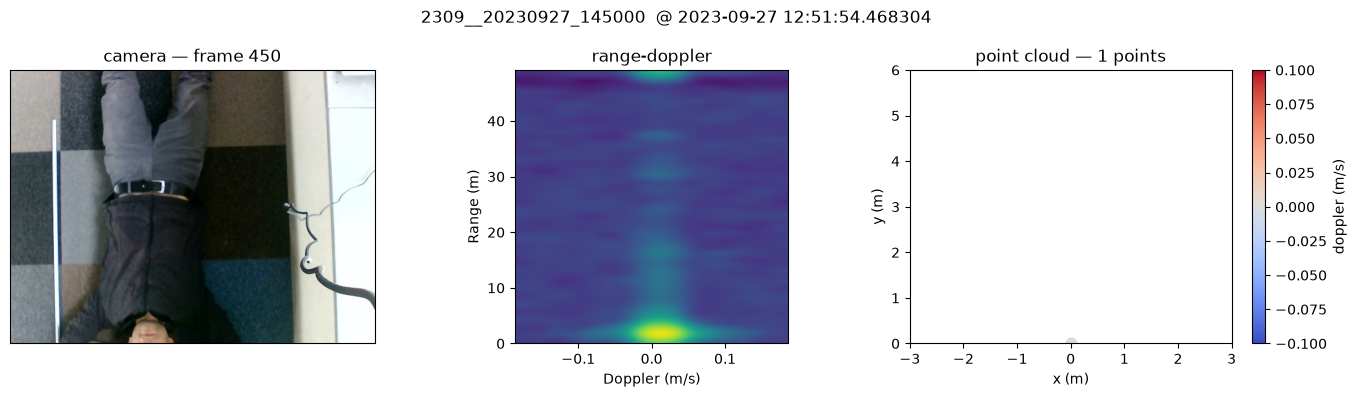

In [8]:
def show_frame(frames, i, sensor=None, title=None):
    '''Camera, range-doppler heatmap and point cloud for one frame.'''
    f = frames[i]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))

    img = np.asarray(f.image)
    if img.size:
        ax[0].imshow(img)
    else:
        ax[0].text(0.5, 0.5, "no image", ha="center")
    ax[0].set_xticks([]); ax[0].set_yticks([])
    ax[0].set_title(f"camera — frame {i}")

    heat = f.output.range_doppler_heatmap
    if sensor is not None:
        RangeDoppler(heat, sensor)._plot_heatmap(ax[1], plot_colorbar=False)
    else:
        ax[1].imshow(np.asarray(heat), aspect="auto")
    ax[1].set_title("range-doppler")

    pc = np.asarray(f.output.pointcloud, dtype=float)
    if pc.ndim == 2 and len(pc):
        sc = ax[2].scatter(pc[:, 0], pc[:, 1], c=pc[:, 3], s=60, cmap="coolwarm")
        plt.colorbar(sc, ax=ax[2], label="doppler (m/s)")
    ax[2].set_xlim(-3, 3); ax[2].set_ylim(0, 6)
    ax[2].set_xlabel("x (m)"); ax[2].set_ylabel("y (m)")
    ax[2].set_title(f"point cloud — {0 if pc.ndim < 2 else len(pc)} points")

    fig.suptitle(title or f"{REC}  @ {f.timestamp}")
    plt.tight_layout()
    return fig


sensor = ds.config.sensor() if ds.config else None
show_frame(frames, len(frames) // 2, sensor);

Step through the recording to see how little changes while someone lies still:

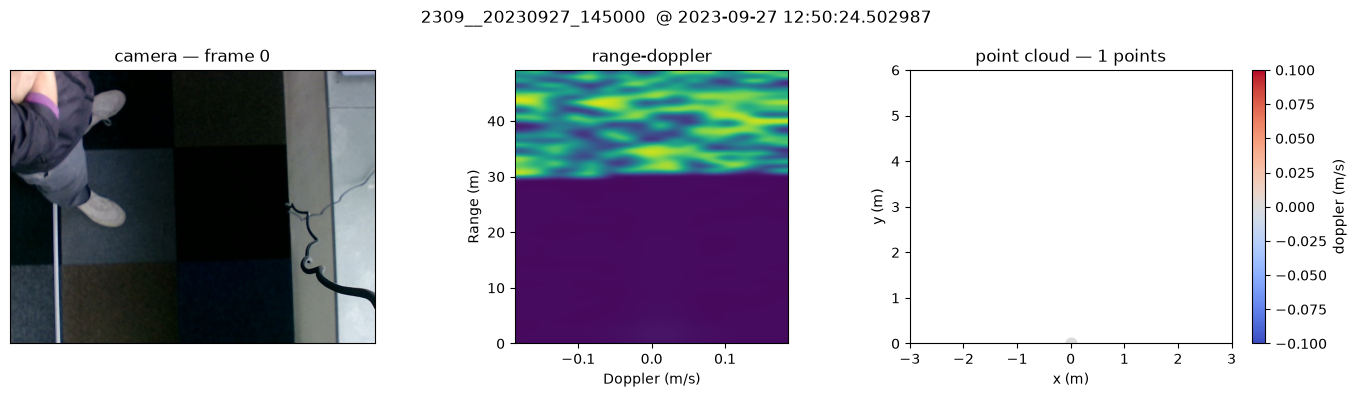

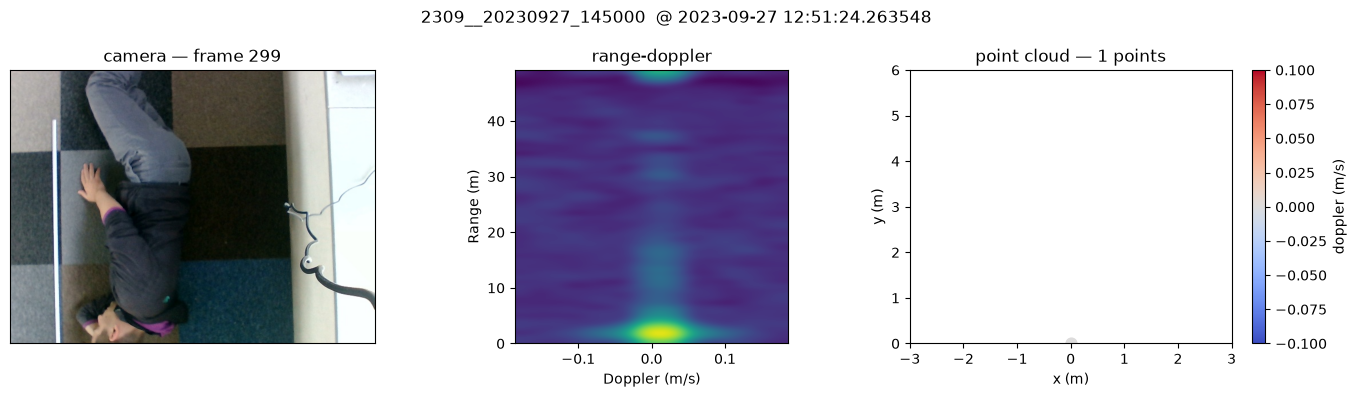

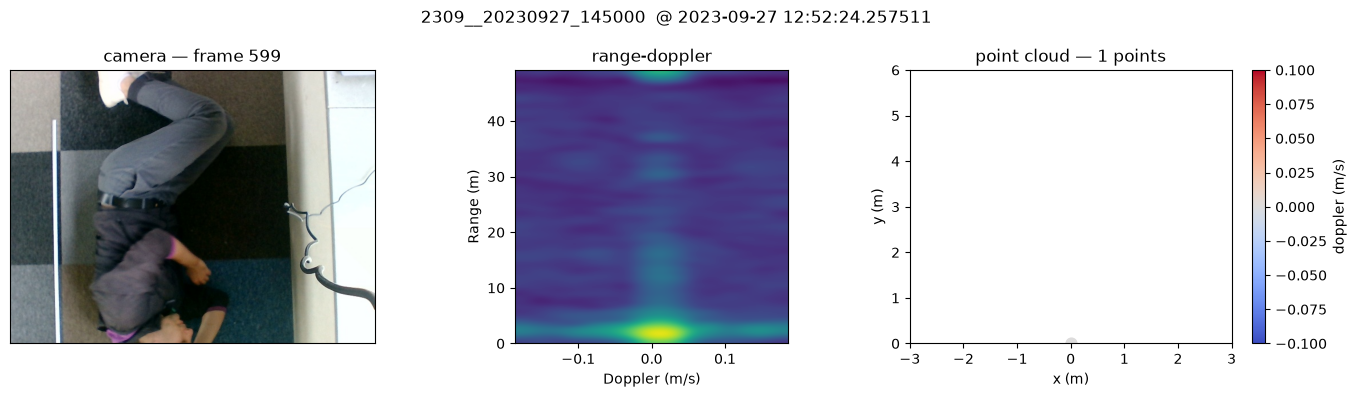

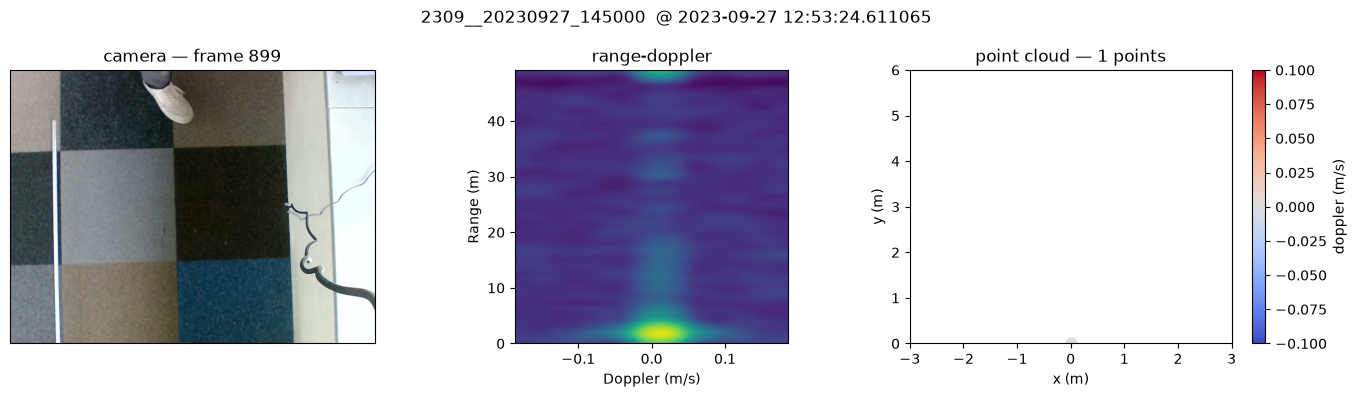

In [9]:
for i in np.linspace(0, len(frames) - 1, 4).astype(int):
    show_frame(frames, int(i), sensor)

## 5. The whole recording at a glance

One frame tells you little. Stacking every frame's range profile over time shows
the structure: a still body is a horizontal band, and movement smears across it.

range-time image: (900, 64) (frames x range bins)


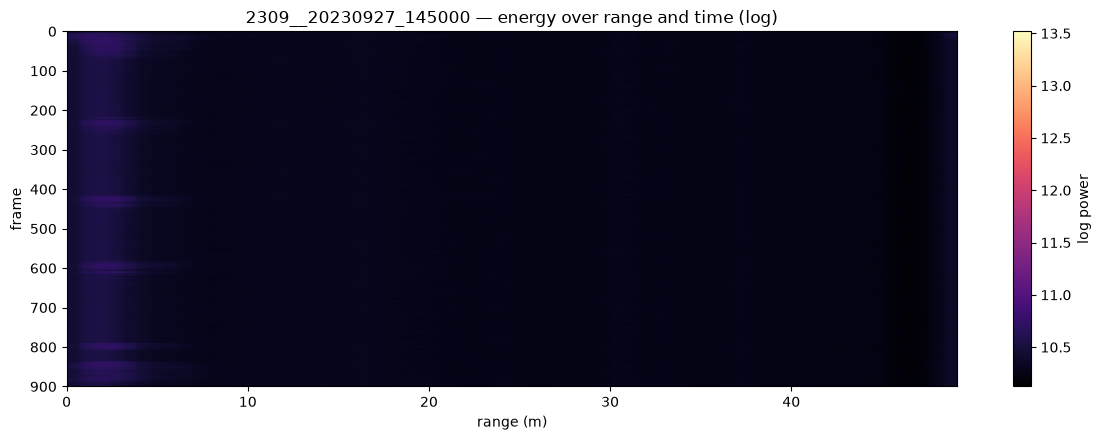

In [10]:
def range_time(frames, sensor=None, doppler="sum"):
    '''(frames x range) image: how energy at each range evolves over time.'''
    H = []
    for f in frames:
        h = np.asarray(f.output.range_doppler_heatmap, dtype=float)
        if h.ndim != 2:
            continue
        H.append(h.sum(axis=1) if doppler == "sum" else h[:, 0])
    return np.asarray(H)


rt = range_time(frames, sensor)
print("range-time image:", rt.shape, "(frames x range bins)")

fig, ax = plt.subplots(figsize=(12, 4.5))
extent = None
if sensor is not None:
    extent = (0, max(sensor.range_bins), len(rt), 0)
im = ax.imshow(np.log1p(rt), aspect="auto", extent=extent, cmap="magma")
ax.set_xlabel("range (m)" if extent else "range bin")
ax.set_ylabel("frame")
ax.set_title(f"{REC} — energy over range and time (log)")
plt.colorbar(im, ax=ax, label="log power")
plt.tight_layout()
plt.show()

The bright horizontal band is the person: constant range, because they are not
going anywhere. Where the band wobbles or brightens, they moved.

## 6. How sparse is the point cloud, really

points per frame: mean 1.0, median 1, max 2, empty frames 0.0%


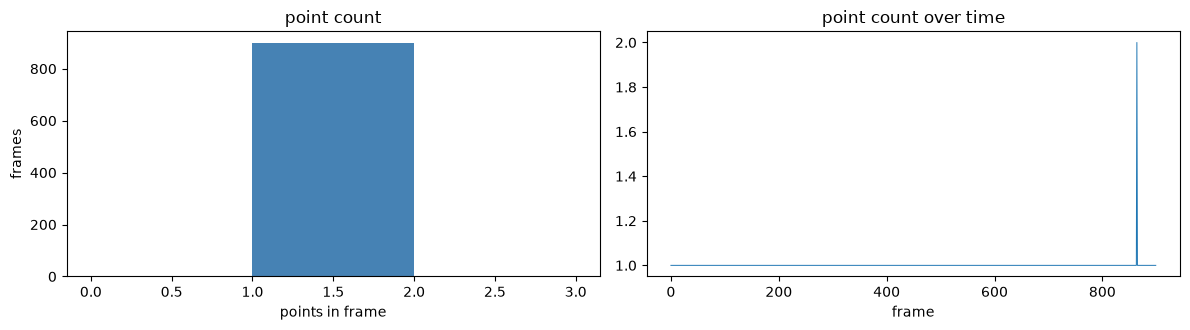

In [11]:
npts = np.array([len(np.asarray(f.output.pointcloud)) for f in frames])
print(f"points per frame: mean {npts.mean():.1f}, median {np.median(npts):.0f}, "
      f"max {npts.max()}, empty frames {100 * (npts == 0).mean():.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(npts, bins=range(0, npts.max() + 2), color="steelblue")
ax[0].set_xlabel("points in frame"); ax[0].set_ylabel("frames"); ax[0].set_title("point count")
ax[1].plot(npts, lw=0.7)
ax[1].set_xlabel("frame"); ax[1].set_title("point count over time")
plt.tight_layout()
plt.show()

A handful of points per frame, against a walking person's 40-90. Whatever you
build has to cope with that.

**Check the points are real before trusting that count.** Ten of the configs
(`guiMonitor -1 0 ...`, including `Experiment_1.cfg`) had point-cloud output
switched off. Those recordings carry one placeholder point at (0, 0, 0) per
frame, so "1 point per frame" there means *no* point cloud, not a sparse one.

## 7. Where the points land

total points: 901


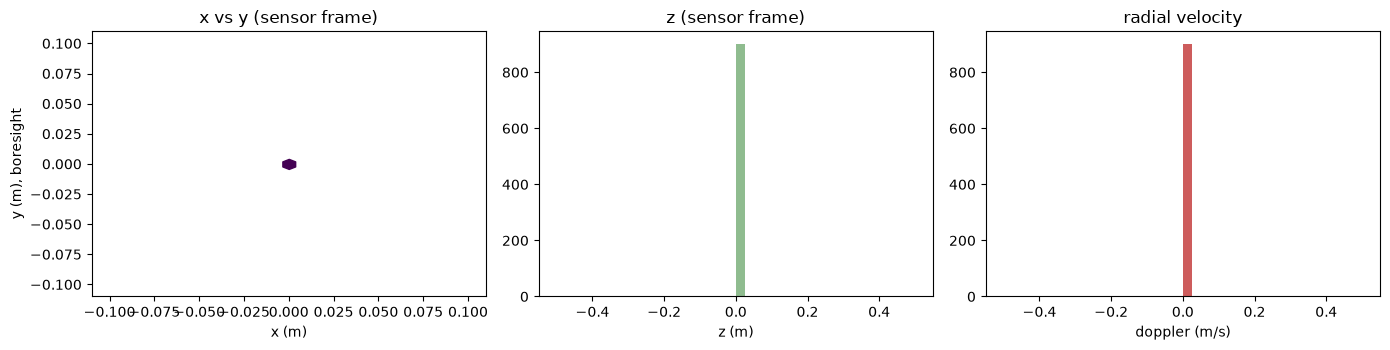

In [12]:
pcs = [np.asarray(f.output.pointcloud, dtype=float) for f in frames]
pcs = [p for p in pcs if p.ndim == 2 and len(p)]
allp = np.vstack(pcs) if pcs else np.zeros((0, 7))
print("total points:", len(allp))

if len(allp):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].hexbin(allp[:, 0], allp[:, 1], gridsize=28, cmap="viridis", mincnt=1)
    ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("y (m), boresight"); ax[0].set_title("x vs y (sensor frame)")
    ax[1].hist(allp[:, 2], bins=40, color="darkseagreen")
    ax[1].set_xlabel("z (m)"); ax[1].set_title("z (sensor frame)")
    ax[2].hist(allp[:, 3], bins=40, color="indianred")
    ax[2].set_xlabel("doppler (m/s)"); ax[2].set_title("radial velocity")
    plt.tight_layout()
plt.show()

Doppler piles up at zero — a still person. That is the signal you are working
with, and it is why a movement-based detector finds nothing here.

The coordinates are the radar's own frame, not the room's: none of the configs
sets `sensorPosition`, so nothing rotates them. With the radar on the ceiling
looking down, **y (boresight) is the distance from the radar toward the floor**,
and x and z are the two floor directions. So a real top-down view is x vs z, and
"height above the floor" is roughly mounting height minus y.

## 8. Comparing recordings

Different configs, different rooms, different people. Here is one mid-recording
frame from several recordings side by side.

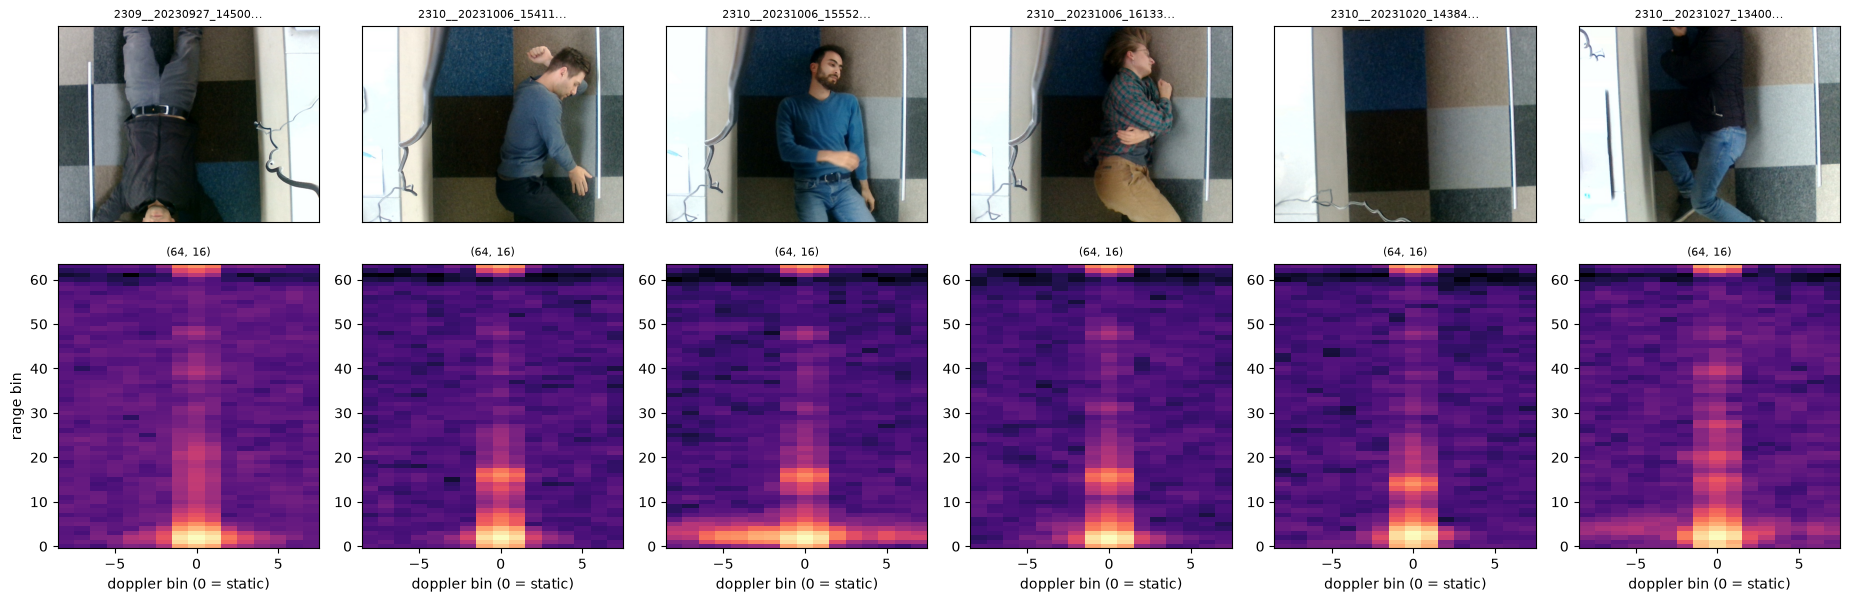

In [13]:
picks = present.dataset.tolist()[:6]
n = len(picks)
fig, axes = plt.subplots(2, n, figsize=(3.1 * n, 6.4))
axes = np.atleast_2d(axes)
for j, rec in enumerate(picks):
    fr = frames_of(rec)
    if not fr:
        continue
    f = fr[len(fr) // 2]
    img = np.asarray(f.image)
    if img.size:
        axes[0, j].imshow(img)
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
    axes[0, j].set_title(rec[:20] + "...", fontsize=8)
    # TI stores doppler in FFT order (zero velocity at column 0, negative
    # velocities wrapped to the top columns); fftshift puts zero in the middle.
    h = np.fft.fftshift(np.asarray(f.output.range_doppler_heatmap, dtype=float), axes=1)
    nd = h.shape[1]
    axes[1, j].imshow(np.log1p(h), aspect="auto", cmap="magma", origin="lower",
                      extent=(-nd // 2 - 0.5, nd // 2 - 0.5, -0.5, h.shape[0] - 0.5))
    axes[1, j].set_title(f"{h.shape}", fontsize=8)
    axes[1, j].set_xlabel("doppler bin (0 = static)")
    if j == 0:
        axes[1, j].set_ylabel("range bin")
plt.tight_layout()
plt.show()

## 9. Labels, where they exist

Some recordings carry labels under `labels/`. They came from more than one tool
over the campaign and the boundaries around a posture change are approximate, so
treat them as a reference rather than ground truth.

```
0 = moving    1 = back    2 = side    3 = front    99 = standing
```

In [14]:
NAMES = {0: "moving", 1: "back", 2: "side", 3: "front", 99: "standing"}

def load_labels(rec):
    '''Per-frame labels for a recording, and the frame order they go with.

    Returns (values, filename, order). The repaired CSVs are keyed on
    (session, frame_num) -- sorting on that is capture order, which is why the
    caller asks frames_of() for the same. The .npy fallbacks carry no key at
    all, so they only line up against the raw file order.
    '''
    d = rec_dir(rec)
    for cand in ("state_labels.csv", "labels.csv", "3_classes.csv", "2_classes.csv"):
        p = os.path.join(d, "labels", cand)
        if os.path.isfile(p):
            df = pd.read_csv(p)
            if {"session", "frame_num"} <= set(df.columns):
                df = df.sort_values(["session", "frame_num"])
            col = "label" if "label" in df.columns else df.columns[-1]
            return pd.to_numeric(df[col], errors="coerce").values, cand, "capture"
    npys = glob.glob(os.path.join(d, "**", "*.npy"), recursive=True)
    if npys:
        # plain integer arrays, so no allow_pickle (which would be a code-execution path)
        return np.load(npys[0]).astype(float), os.path.basename(npys[0]), "file"
    return None, None, None


labelled = present[present.has_labels].dataset.tolist()
print("recordings with labels here:", len(labelled))
for rec in labelled[:5]:
    lab, src, _ = load_labels(rec)
    if lab is None:
        continue
    counts = {NAMES.get(int(v), int(v)): int((lab == v).sum()) for v in np.unique(lab[~np.isnan(lab)])}
    print(f"  {rec[:44]:46} {src:20} {counts}")


recordings with labels here: 14
  2310__20231006_154117                          labels.npy           {'moving': 403, 'back': 1091, 'side': 1106}
  2311__20231115_135843                          state_labels.csv     {'moving': 535, 'back': 236, 'side': 467, 'front': 263, 'standing': 99}
  2311__20231115_140642                          state_labels.csv     {'moving': 795, 'back': 193, 'side': 343, 'front': 193, 'standing': 76}
  2311__20231120_144541                          state_labels.csv     {'moving': 1071, 'back': 151, 'side': 269, 'front': 137, 'standing': 272}
  2311__20231120_145729                          state_labels.csv     {'moving': 641, 'back': 286, 'side': 520, 'front': 238, 'standing': 115}


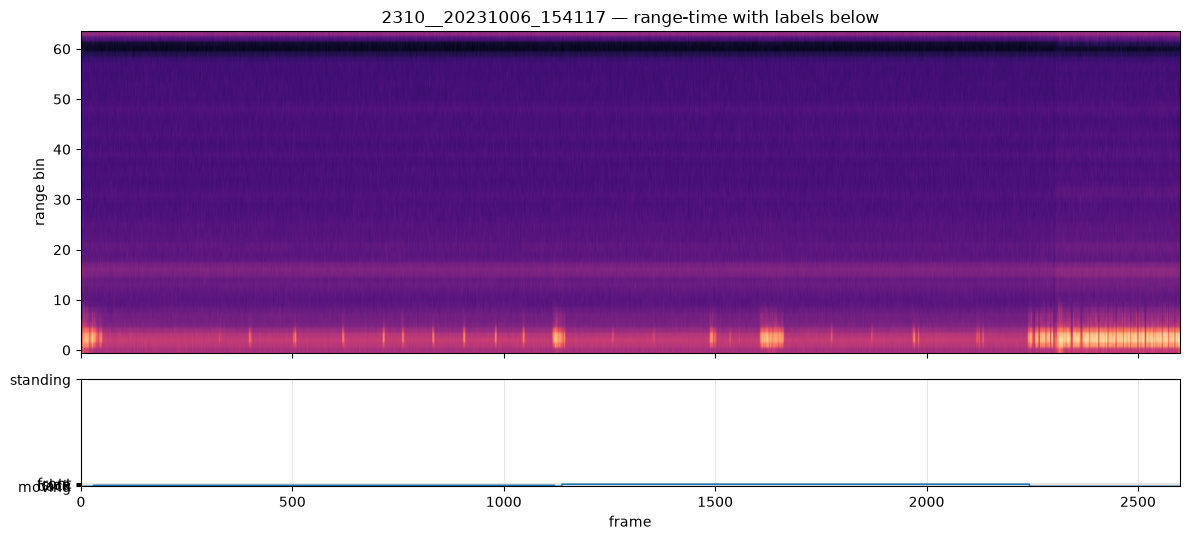

In [15]:
if labelled:
    rec = labelled[0]
    lab, src, order = load_labels(rec)
    fr = frames_of(rec, order)
    n = min(len(fr), len(lab))
    rt = range_time(fr[:n])

    fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True,
                           gridspec_kw={"height_ratios": [3, 1]})
    ax[0].imshow(np.log1p(rt).T, aspect="auto", cmap="magma", origin="lower")
    ax[0].set_ylabel("range bin"); ax[0].set_title(f"{rec} — range-time with labels below")
    ax[1].plot(lab[:n], lw=1.2)
    ax[1].set_yticks(sorted(NAMES)); ax[1].set_yticklabels([NAMES[k] for k in sorted(NAMES)])
    ax[1].set_xlabel("frame"); ax[1].grid(alpha=.3)
    plt.tight_layout()
plt.show()


Where the label track holds steady, the range-time band is flat; the `moving`
stretches line up with the smeared parts.

## 10. Reading the raw file, no package

If you would rather not use the reader at all, a chunk is a plain DataFrame:
`frame` holds the raw radar payload, `image` the JPEG bytes.

In [16]:
chunk = sorted(glob.glob(os.path.join(rec_dir(REC), "*.h5")))[0]
raw = pd.read_hdf(chunk)
print(os.path.basename(chunk), "->", list(raw.columns), f"{len(raw)} rows")
raw.head(3)

data_0.h5 -> ['frame', 'timestamp', 'image'] 100 rows


,frame,timestamp,image
0,"[2, 1, 4, 3, 6, 5, 8, 7, 0, 0, 6, 3, 64, 8, 0,...",2023-09-27 12:50:24.502987,"[255, 216, 255, 224, 0, 16, 74, 70, 73, 70, 0,..."
1,"[2, 1, 4, 3, 6, 5, 8, 7, 0, 0, 6, 3, 64, 8, 0,...",2023-09-27 12:50:24.662259,"[255, 216, 255, 224, 0, 16, 74, 70, 73, 70, 0,..."
2,"[2, 1, 4, 3, 6, 5, 8, 7, 0, 0, 6, 3, 64, 8, 0,...",2023-09-27 12:50:24.869490,"[255, 216, 255, 224, 0, 16, 74, 70, 73, 70, 0,..."


## Where to go next

Some directions worth trying:

- **Is anyone there?** Separate the empty-room recordings from the occupied
  ones. The `*_environment` recordings are background with nobody in the scene.
- **Where are they?** The range-time plot shows the person as a band; turning
  that into a position estimate is a good warm-up.
- **Which way are they lying?** The hard one. Start from the heatmap, and mind
  the differing geometries between recordings.
- **Does it survive a room change?** `room2` is the same rig elsewhere. Anything
  that works in `room1` and collapses in `room2` has learnt the room, not the
  person.

Whatever you build, split by **recording** rather than by frame: at 5 fps (10 fps for the `Config_5`
recordings), neighbouring frames are near-copies, and mixing them across a split will make a
weak model look excellent.